In [4]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import tkinter as tk
from PIL import Image, ImageTk
import scipy as sp
from scipy.special import jv
from scipy.optimize import brentq

1. Generating a matrix similar to the resolution of the SLM device - we are using HAMAMATSU LSH0805097
Resolution: 600 x 800

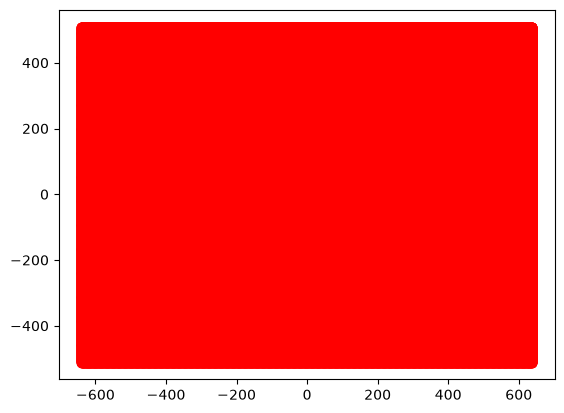

In [5]:
H = 1280 #horizontal pixels - these are not the same as the camera yet so need to be changed
V = 1024 #vertical pixels

x = np.arange(-H/2,H/2-1,1)
y = np.arange(-V/2,V/2-1,1)

xv,yv = np.meshgrid(x,y) #surface area for the hologram - should be similar to that of SLMs resolution

phi = np.angle(xv + 1j * yv, deg=False) #azimuthal angle 
l = 2 #topological charge
# print(phi)
nx = 100 #number of horizontal and vertical grooves
ny = 100

gx = nx/H
gy = nx/V

plt.plot(xv,yv, marker='o', color='r', linestyle='none')
plt.show()

# plt.imshow(x,y)

2. Now that we have made a mesh similar to the size of the SLM screen, we encode a hologram on to it.

[[26.55669855 29.41896948 32.28113662 ... 36.66155161 39.52351048
  42.3855736 ]
 [30.27051784 33.13281212 35.99500251 ... 40.2393105  43.10129238
  45.96337863]
 [33.98444079 36.84675867 39.70897254 ... 43.81696478 46.67896991
  49.54107952]
 [37.69846752 40.56080923 43.42304681 ... 47.39451433 50.25654295
  53.11867616]
 [41.41259815 44.27496392 47.13722545 ... 50.97195905 53.83401139
  56.69616844]]


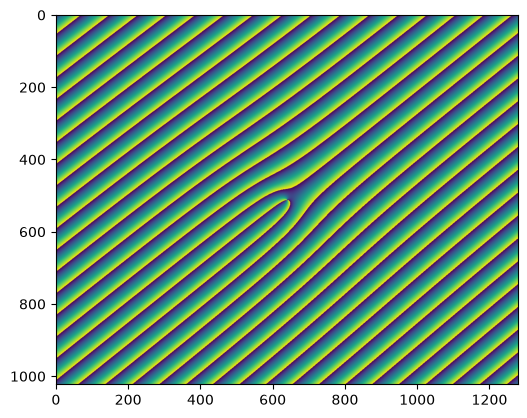

In [ ]:
#1. Vortex Beam
zoom = 6
Hol_vortex = np.mod(-l*phi+2*np.pi*(gy*yv/zoom + gx*xv/zoom),2*np.pi) #if I divide the yv and xv in the formula by a factor (it zooms in to the hologram)

#2. Bessel Beam


SLM_vortex = Hol_vortex/np.max(Hol_vortex) * 224 #grayscale normalisation

print(SLM_vortex[:5])
plt.imshow(SLM_vortex)
plt.show()

In [7]:
print(matplotlib.get_backend())

module://matplotlib_inline.backend_inline


3. Plotting the hologram on the second screen (the SLM)

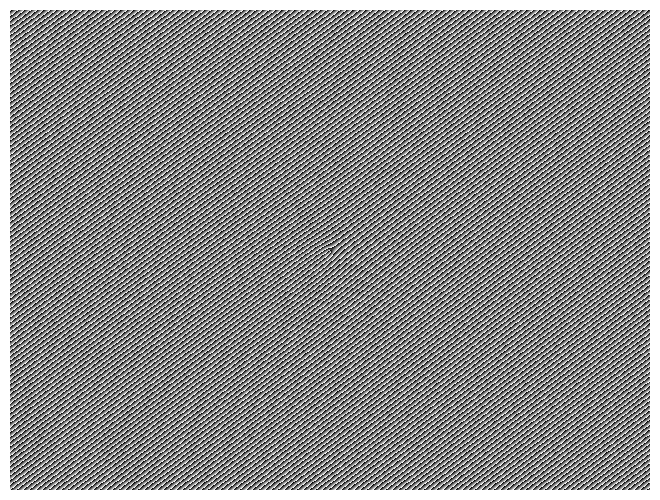

In [8]:
fig = plt.figure(1)

# Get the figure manager
manager = plt.get_current_fig_manager()

# Set window position if supported by the backend
if hasattr(manager, "window"):
    window = manager.window
    if hasattr(window, "wm_geometry"):  # Tkinter
        window.wm_geometry("+1200+0")
    elif hasattr(window, "setGeometry"):  # Qt
        window.setGeometry(1920, 0, 1280, 1024)

# Remove axes margins and display the SLM
ax = fig.add_axes([0, 0, 1, 1])
ax.imshow(SLM_vortex, cmap="gray", interpolation="nearest", aspect="auto")
ax.axis("off")

plt.show()

In [9]:
# # Convert SLM array to 8-bit grayscale
# image = np.asarray(SLM_vortex)

# if image.dtype != np.uint8:
#     image = np.clip(image, 0, 255).astype(np.uint8)

# pil_image = Image.fromarray(image, mode="L")

# # Create a borderless window
# root = tk.Tk()
# root.overrideredirect(True)

# # Set the position to your SLM monitor
# x, y = -300, 0
# root.geometry(f"{image.shape[1]}x{image.shape[0]}+{x}+{y}")

# # Display the image without margins
# photo = ImageTk.PhotoImage(pil_image)
# label = tk.Label(root, image=photo, borderwidth=0)
# label.pack()

# # Press Escape to close the window
# root.bind("<Escape>", lambda event: root.destroy())

# root.mainloop()

In [ ]:
# Check the image
image = np.asarray(SLM_vortex)

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Image range:", image.min(), image.max())

# Ensure an 8-bit grayscale image
image = np.clip(image, 0, 224).astype(np.uint8)
pil_image = Image.fromarray(image)

# Create display window
root = tk.Tk()
root.overrideredirect(True)
root.attributes("-topmost", True)

height, width = image.shape[:2]

# SLM monitor position
x, y = 1920, 0
root.geometry(f"{width}x{height}+{x}+{y}")

photo = ImageTk.PhotoImage(pil_image)
label = tk.Label(root, image=photo, borderwidth=0, highlightthickness=0)
label.pack()

root.bind("<Escape>", lambda event: root.destroy())

print("Window geometry:", root.geometry())
root.mainloop()

Image shape: (1023, 1279)
Image dtype: float64
Image range: 0.0 224.0
Window geometry: 1x1+1920+0


In [ ]:
from screeninfo import get_monitors

for i, m in enumerate(get_monitors()):
    print(
        f"Monitor {i}: "
        f"x={m.x}, y={m.y}, "
        f"width={m.width}, height={m.height}"
    )

Monitor 0: x=0, y=0, width=1920, height=1080
Monitor 1: x=1920, y=0, width=1280, height=1024


C:\Users\Manip\AppData\Local\Temp\ipykernel_32436\2457114565.py:8: RuntimeWarning: overflow encountered in exp
  E_in = A0*np.exp(2*np.pi*omega)


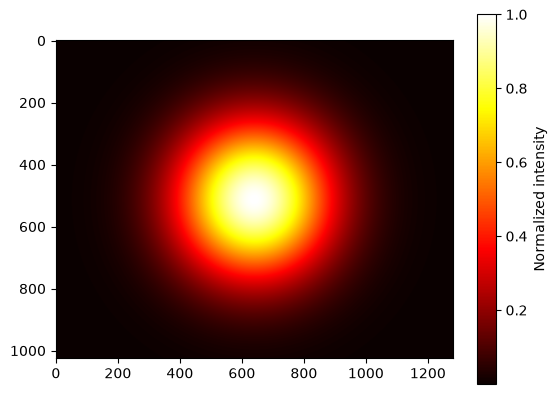

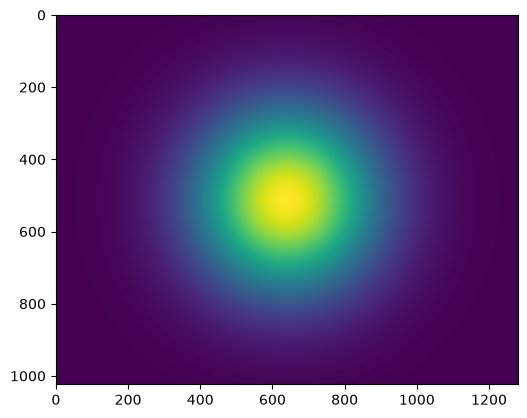

In [ ]:
#Defining the input beam
lambda0 = 520e-9 #nm
c = 3e8 
omega = 2*np.pi*c/lambda0

A0 = 2

E_in = A0*np.exp(2*np.pi*omega)

Nx, Ny = 1280, 1024

# Beam center (pixels)
x0, y0 = Nx / 2, Ny / 2

w = 250

# Pixel coordinate grids
x = np.arange(Nx)
y = np.arange(Ny)
X, Y = np.meshgrid(x, y)

# Gaussian electric-field amplitude
A_rel = np.exp(-((X-x0)**2 + (Y-y0)**2) / w**2) #max amplitude is at the center 

a = 0.5
#Inverting the Bessel function to extract f(A_rel)
def g(f):
    j1(f) - a * A_rel

f = brentq(g, 1.841183781)
# Gaussian intensity
I = E**2

# Display intensity
plt.imshow(E, cmap="hot", origin="upper")
plt.colorbar(label="Normalized intensity")
plt.show()

E_norm = E/np.max(E) * 224

plt.imshow(E_norm)
plt.show()

# # Check the image
# image = np.asarray(I)

# print("Image shape:", image.shape)
# print("Image dtype:", image.dtype)
# print("Image range:", image.min(), image.max())

# # Ensure an 8-bit grayscale image
# image = np.clip(image, 0, 224).astype(np.uint8)
# pil_image = Image.fromarray(image)

# # Create display window
# root = tk.Tk()
# root.overrideredirect(True)
# root.attributes("-topmost", True)

# height, width = image.shape[:2]

# # SLM monitor position
# x, y = 1920, 0
# root.geometry(f"{width}x{height}+{x}+{y}")

# photo = ImageTk.PhotoImage(pil_image)
# label = tk.Label(root, image=photo, borderwidth=0, highlightthickness=0)
# label.pack()

# root.bind("<Escape>", lambda event: root.destroy())

# print("Window geometry:", root.geometry())
# root.mainloop()

In [ ]:
E_rel = 4 * np.exp(-((X-x0)**2 + (Y-y0)**2) / w**2)
A_rel = 4

print(A_rel)

[[8.59616201e-05 8.77388614e-05 8.95499812e-05 ... 9.13955618e-05
  8.95499812e-05 8.77388614e-05]
 [8.73802181e-05 8.91867886e-05 9.10277968e-05 ... 9.29038344e-05
  9.10277968e-05 8.91867886e-05]
 [8.88193844e-05 9.06557095e-05 9.25270393e-05 ... 9.44339756e-05
  9.25270393e-05 9.06557095e-05]
 ...
 [9.02793651e-05 9.21458750e-05 9.40479651e-05 ... 9.59862468e-05
  9.40479651e-05 9.21458750e-05]
 [8.88193844e-05 9.06557095e-05 9.25270393e-05 ... 9.44339756e-05
  9.25270393e-05 9.06557095e-05]
 [8.73802181e-05 8.91867886e-05 9.10277968e-05 ... 9.29038344e-05
  9.10277968e-05 8.91867886e-05]]
